# Diagnósticos de regressão linear — statsmodels

Notebook adaptado da documentação do statsmodels, com os nomes das variáveis dos dados traduzidos para português. O código próprio, seus comentários, suas docstrings e os rótulos dos gráficos foram adaptados para português. Os textos explicativos originais fora do código permanecem em inglês. Nomes e argumentos exigidos pelas bibliotecas foram preservados.

- **Fonte:** [Linear regression diagnostics](https://www.statsmodels.org/stable/examples/notebooks/generated/linear_regression_diagnostics_plots.html).
- **Arquivo original:** [notebook disponibilizado pela documentação](https://www.statsmodels.org/stable/_sources/examples/notebooks/generated/linear_regression_diagnostics_plots.ipynb.txt).
- **Data de acesso:** 27/10/2026.
- **Objetivo:** reproduzir gráficos de diagnóstico de regressão linear e a tabela de fatores de inflação da variância (VIF).
- **Pré-requisitos:** fundamentos de regressão linear e Python; bibliotecas pandas, numpy, scipy, statsmodels, matplotlib e seaborn.
- **Execução:** execute as células na ordem apresentada, em um ambiente Jupyter com Python 3. A célula de leitura baixa os dados Advertising da URL indicada no código e exige conexão à internet. Se necessário, instale as dependências com `%pip install pandas numpy scipy statsmodels matplotlib seaborn`.

Os exemplos, explicações e créditos abaixo pertencem à fonte original. As saídas foram recalculadas localmente na criação desta cópia; não constituem resultados de dados da disciplina.


**Adaptação dos nomes:** Sales → Vendas; TV → Televisão; Radio → Rádio; Newspaper → Jornal. A tradução é aplicada após a leitura dos dados e utilizada na fórmula do modelo, no resumo dos resultados e na tabela de VIF. Os valores dos dados permanecem os mesmos.

**Convenção do código:** `dados`, `modelo` e `diagnóstico` representam a tabela, o modelo estimado e o objeto de diagnóstico. Os métodos próprios usam nomes em português; `self`, métodos especiais do Python, aliases usuais (`pd`, `np`, `plt`, `sns`, `smf`) e a API das bibliotecas mantêm sua grafia original.


[![Abrir no Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gustavocxavier/mqcc/blob/main/codigos/unidade2_regressao_linear_graficos_diagnostico.ipynb)

# Diagnósticos de regressão linear

Na vida real, a relação entre as variáveis de resposta e preditoras raramente é linear. Aqui, faremos uso das saídas do `statsmodels` para visualizar e identificar potenciais problemas que podem ocorrer ao ajustar um modelo de `regressão linear` a uma relação não linear. O objetivo principal é reproduzir as visualizações discutidas na seção de Problemas Potenciais (Capítulo 3.3.3) do livro *An Introduction to Statistical Learning* (ISLR) de James et al., Springer.

In [1]:
import pandas as pd

import statsmodels
import statsmodels.formula.api as smf

#### Regressão linear múltipla simples

Primeiramente, vamos carregar os dados de Publicidade (Advertising) do Capítulo 2 do livro ISLR e ajustar um modelo linear a eles.

In [2]:
# Carregar os dados e traduzir os nomes das variáveis
url_dados = "https://raw.githubusercontent.com/nguyen-toan/ISLR/07fd968ea484b5f6febc7b392a28eb64329a4945/dataset/Advertising.csv"
dados = pd.read_csv(url_dados).drop("Unnamed: 0", axis=1)
dados = dados.rename(columns={
    "Sales": "Vendas",
    "TV": "Televisão",
    "Radio": "Rádio",
    "Newspaper": "Jornal",
})
dados.head()

,Televisão,Rádio,Jornal,Vendas
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [13]:
# Estimar o modelo linear com os nomes das variáveis em português
modelo = smf.ols(formula="Vendas ~ Televisão + Rádio + Jornal", data=dados).fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                 Vendas   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           1.58e-96
Time:                        12:40:57   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9389      0.312      9.422      0.0

#### Gráficos e Tabela de Diagnóstico

A seguir, apresentamos primeiro um código base que usaremos posteriormente para gerar os seguintes gráficos de diagnóstico:

    a. resíduos
    b. q-q
    c. escala-localização
    d. alavancagem

e uma tabela:

    a. vif (fator de inflação da variância)

In [15]:
# Ferramentas para os gráficos de diagnóstico e a tabela de VIF.
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from statsmodels.graphics.gofplots import ProbPlot as GraficoProbabilidade
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor as fator_inflacao_variancia,
)
from statsmodels.tools.tools import maybe_unwrap_results as extrair_resultados


class DiagnosticoRegressaoLinear:
    """Produz gráficos de diagnóstico e uma tabela de multicolinearidade.

    Adaptação do exemplo de statsmodels de Prajwal Kafle e Matt Spinelli.
    Créditos originais: Prajwal Kafle (p33ajkafle@gmail.com, substituir 3 por r)
    e Matt Spinelli (m3spinelli@gmail.com, substituir 3 por r).
    O código original é fornecido sem garantia; verifique-o antes de usar.

    As contribuições de Matt Spinelli incluem correções nas anotações dos
    resíduos, ajustes no gráfico de alavancagem, linha horizontal em zero,
    limite de alavancagem 2p/n, critérios de distância de Cook e legenda.
    Os critérios disponíveis são 'baseR', 'convencional' e 'graus_liberdade'.
    """

    def __init__(self, modelo):
        """Recebe um modelo de regressão linear já estimado pelo statsmodels.

        Exemplo de uso:
        >>> diagnostico = DiagnosticoRegressaoLinear(modelo)
        >>> diagnostico.grafico_residuos()
        >>> diagnostico.tabela_vif()
        >>> tabela_vif, figura, eixos = diagnostico()
        """
        if not isinstance(
            modelo, statsmodels.regression.linear_model.RegressionResultsWrapper
        ):
            raise TypeError(
                "O modelo deve ser um resultado de regressão linear do statsmodels."
            )

        self.resultados = extrair_resultados(modelo)
        self.valores_observados = self.resultados.model.endog
        self.valores_ajustados = self.resultados.fittedvalues
        self.variaveis_explicativas = self.resultados.model.exog
        self.nomes_variaveis = self.resultados.model.exog_names
        self.residuos = np.array(self.resultados.resid)
        influencia = self.resultados.get_influence()
        self.residuos_padronizados = influencia.resid_studentized_internal
        self.alavancagem = influencia.hat_matrix_diag
        self.distancia_cook = influencia.cooks_distance[0]
        self.numero_parametros = len(self.resultados.params)
        self.numero_observacoes = len(self.residuos_padronizados)

    def __call__(
        self,
        estilo_grafico="seaborn-v0_8-paper",
        mostrar_limite_alavancagem=False,
        criterio_cook="baseR"
    ):
        """Exibe os quatro gráficos e retorna tabela de VIF, figura e eixos."""
        if estilo_grafico not in plt.style.available:
            estilo_grafico = "default"
        with plt.style.context(estilo_grafico):
            figura, eixos = plt.subplots(nrows=2, ncols=2, figsize=(10, 10))
            self.grafico_residuos(eixo=eixos[0, 0])
            self.grafico_qq(eixo=eixos[0, 1])
            self.grafico_escala_localizacao(eixo=eixos[1, 0])
            self.grafico_alavancagem(
                eixo=eixos[1, 1],
                mostrar_limite_alavancagem=mostrar_limite_alavancagem,
                criterio_cook=criterio_cook,
            )
            plt.show()
        return self.tabela_vif(), figura, eixos

    def grafico_residuos(self, eixo=None):
        """Compara resíduos e valores ajustados para investigar não linearidade.

        Uma curva suavizada aproximadamente horizontal, em torno de zero,
        é compatível com a ausência de um padrão sistemático nos resíduos.
        """
        if eixo is None:
            figura, eixo = plt.subplots()
        sns.residplot(
            x=self.valores_ajustados, y=self.residuos, lowess=True,
            scatter_kws={"alpha": 0.5},
            line_kws={"color": "red", "lw": 1, "alpha": 0.8}, ax=eixo,
        )
        # Identificar as três observações com os maiores resíduos absolutos.
        residuos_absolutos = np.abs(self.residuos)
        indices_ordenados = np.flip(np.argsort(residuos_absolutos), 0)
        for indice in indices_ordenados[:3]:
            eixo.annotate(
                indice, xy=(self.valores_ajustados[indice], self.residuos[indice]),
                color="C3",
            )
        eixo.set_title("Resíduos versus valores ajustados", fontweight="bold")
        eixo.set_xlabel("Valores ajustados")
        eixo.set_ylabel("Resíduos")
        return eixo

    def grafico_qq(self, eixo=None):
        """Compara resíduos padronizados e quantis teóricos da normal.

        Pontos próximos da diagonal são compatíveis com normalidade.
        """
        if eixo is None:
            figura, eixo = plt.subplots()
        grafico_probabilidade = GraficoProbabilidade(self.residuos_padronizados)
        grafico_probabilidade.qqplot(line="45", alpha=0.5, lw=1, ax=eixo)
        indices_ordenados = np.flip(
            np.argsort(np.abs(self.residuos_padronizados)), 0
        )
        # Posicionar os rótulos dos três maiores resíduos na ordem dos quantis.
        for indice, x, y in self.__coordenadas_residuos_qq(
            grafico_probabilidade.theoretical_quantiles, indices_ordenados[:3]
        ):
            eixo.annotate(indice, xy=(x, y), ha="right", color="C3")
        eixo.set_title("Gráfico Q-Q normal", fontweight="bold")
        eixo.set_xlabel("Quantis teóricos")
        eixo.set_ylabel("Resíduos padronizados")
        return eixo

    def grafico_escala_localizacao(self, eixo=None):
        """Investiga a homoscedasticidade a partir da dispersão dos resíduos.

        Uma curva aproximadamente horizontal é compatível com variância constante.
        """
        if eixo is None:
            figura, eixo = plt.subplots()
        raiz_residuos_absolutos = np.sqrt(np.abs(self.residuos_padronizados))
        eixo.scatter(self.valores_ajustados, raiz_residuos_absolutos, alpha=0.5)
        sns.regplot(
            x=self.valores_ajustados, y=raiz_residuos_absolutos,
            scatter=False, ci=False, lowess=True,
            line_kws={"color": "red", "lw": 1, "alpha": 0.8}, ax=eixo,
        )
        indices_ordenados = np.flip(np.argsort(raiz_residuos_absolutos), 0)
        for indice in indices_ordenados[:3]:
            eixo.annotate(
                indice,
                xy=(self.valores_ajustados[indice], raiz_residuos_absolutos[indice]),
                color="C3",
            )
        eixo.set_title("Escala-localização", fontweight="bold")
        eixo.set_xlabel("Valores ajustados")
        eixo.set_ylabel(r"$\sqrt{|\mathrm{Resíduos\ padronizados}|}$")
        return eixo

    def grafico_alavancagem(
        self, eixo=None, mostrar_limite_alavancagem=False, criterio_cook="baseR"
    ):
        """Compara resíduos e alavancagem e mostra curvas de distância de Cook.

        Pontos além das curvas merecem investigação quanto à influência no ajuste.
        Os limites são regras práticas e não determinam exclusão automática.
        """
        if eixo is None:
            figura, eixo = plt.subplots()
        eixo.scatter(self.alavancagem, self.residuos_padronizados, alpha=0.5)
        sns.regplot(
            x=self.alavancagem, y=self.residuos_padronizados,
            scatter=False, ci=False, lowess=True,
            line_kws={"color": "red", "lw": 1, "alpha": 0.8}, ax=eixo,
        )
        # Destacar as três maiores distâncias de Cook.
        indices_influentes = np.flip(np.argsort(self.distancia_cook), 0)[:3]
        for indice in indices_influentes:
            eixo.annotate(
                indice,
                xy=(self.alavancagem[indice], self.residuos_padronizados[indice]),
                color="C3",
            )
        if criterio_cook == "baseR" or  criterio_cook is None:
            fatores = [1, 0.5]
        elif  criterio_cook == "convencional":
            fatores = [4 / self.numero_observacoes]
        elif  criterio_cook == "graus_liberdade":
            fatores = [4 / (self.numero_observacoes - self.numero_parametros)]
        else:
            raise ValueError(
                "O critério de Cook deve ser 'baseR', 'convencional' "
                "ou 'graus_liberdade'."
            )
        for indice, fator in enumerate(fatores):
            rotulo = "Distância de Cook" if indice == 0 else None
            valores_x, valores_y = self.__curva_distancia_cook(fator)
            eixo.plot(
                valores_x, valores_y, label=rotulo, lw=1.25, ls="--", color="red"
            )
            eixo.plot(
                valores_x, np.negative(valores_y), lw=1.25, ls="--", color="red"
            )
        if mostrar_limite_alavancagem:
            limite_alavancagem = 2 * self.numero_parametros / self.numero_observacoes
            if max(self.alavancagem) > limite_alavancagem:
                eixo.axvline(
                    limite_alavancagem, label="Alavancagem elevada",
                    ls="-.", color="purple", lw=1,
                )
        eixo.axhline(0, ls="dotted", color="black", lw=1.25)
        eixo.set_xlim(0, max(self.alavancagem) + 0.01)
        eixo.set_ylim(
            min(self.residuos_padronizados) - 0.1,
            max(self.residuos_padronizados) + 0.1,
        )
        eixo.set_title("Resíduos versus alavancagem", fontweight="bold")
        eixo.set_xlabel("Alavancagem")
        eixo.set_ylabel("Resíduos padronizados")
        eixo.legend(loc="best")
        return eixo

    def tabela_vif(self):
        """Calcula o fator de inflação da variância para cada coluna do modelo.

        VIF acima de 5 é uma regra prática para investigar multicolinearidade.
        A interpretação depende do contexto e da especificação do modelo.
        """
        tabela = pd.DataFrame()
        tabela["Variável"] = self.nomes_variaveis
        tabela["Fator VIF"] = [
            fator_inflacao_variancia(self.variaveis_explicativas, indice)
            for indice in range(self.variaveis_explicativas.shape[1])
        ]
        return tabela.sort_values("Fator VIF").round(2)

    def __curva_distancia_cook(self, fator):
        """Calcula as coordenadas de uma curva de distância de Cook."""
        numero_parametros = self.numero_parametros

        def calcular_residuo(x):
            return np.sqrt((fator * numero_parametros * (1 - x)) / x)

        valores_x = np.linspace(0.001, max(self.alavancagem), 50)
        valores_y = calcular_residuo(valores_x)
        return valores_x, valores_y

    def __coordenadas_residuos_qq(self, quantis, indices_maiores_residuos):
        """Fornece índices e coordenadas para anotar os resíduos extremos."""
        deslocamento = 0
        indice_quantil = 0
        anterior_negativo = None
        for indice_residuo in indices_maiores_residuos:
            y = self.residuos_padronizados[indice_residuo]
            negativo = y < 0
            if anterior_negativo is None or anterior_negativo == negativo:
                deslocamento += 1
            else:
                indice_quantil -= deslocamento
            x = (
                quantis[indice_quantil]
                if negativo
                else np.flip(quantis, 0)[indice_quantil]
            )
            indice_quantil += 1
            anterior_negativo = negativo
            yield indice_residuo, x, y


Utilizando o modelo ajustado com os dados de Publicidade acima e o código base fornecido, agora geramos os gráficos de diagnóstico um a um.

In [16]:
diagnostico = DiagnosticoRegressaoLinear(modelo)

**A. Resíduos vs Valores Ajustados**

Ferramenta gráfica para identificar não linearidade.

No gráfico, a linha vermelha (aproximadamente) horizontal é um indicador de que os resíduos possuem um padrão linear.

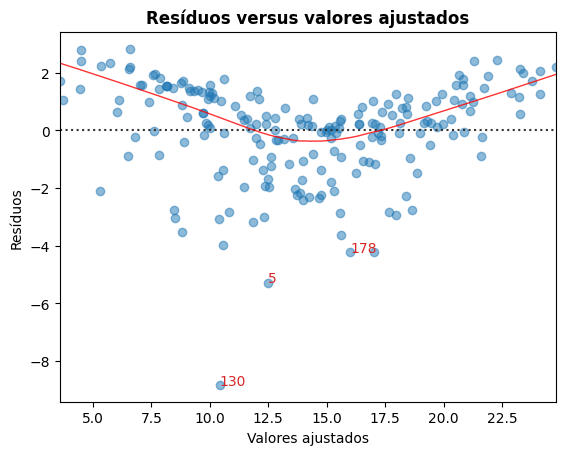

In [17]:
diagnostico.grafico_residuos();

**B. Resíduos Padronizados vs Quantis Teóricos**

Este gráfico é usado para verificar visualmente se os resíduos são distribuídos normalmente.

Pontos distribuídos ao longo da linha diagonal sugerem que sim.

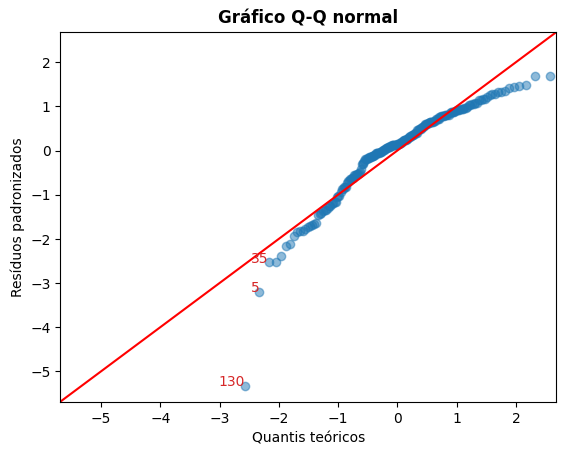

In [18]:
diagnostico.grafico_qq();

**C. Raiz Quadrada dos Resíduos Padronizados vs Valores Ajustados**

Este gráfico é usado para verificar a homocedasticidade dos resíduos.

Uma linha vermelha próxima da horizontal no gráfico sugere que a variância é constante.

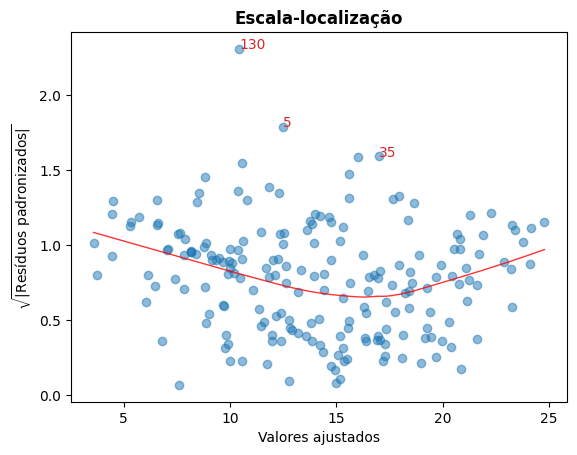

In [19]:
diagnostico.grafico_escala_localizacao();

**D. Resíduos vs Alavancagem**

Pontos que ficam fora das curvas de distância de Cook são considerados observações que podem influenciar fortemente o ajuste (pontos influentes).

O ideal é que não haja pontos fora dessas curvas.

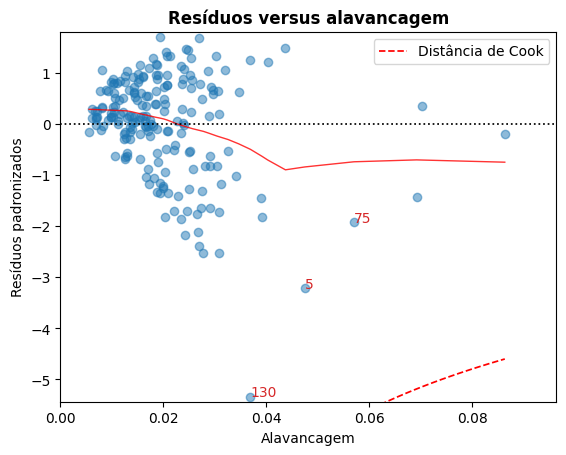

In [20]:
diagnostico.grafico_alavancagem();

As curvas de distância de Cook podem ser traçadas usando outras regras práticas:

| Regra Prática | Limite(s) |
| :----------- | ----------- |
| `'baseR'` (**padrão**) | $$D_i > 1 \mid D_i > 0.5$$ |
| `'convencional'` | $$D_i > { 4 \over n}$$ |
| `'graus_liberdade'` | $$D_i > {4 \over n - k - 1}$$ |

Uma linha de orientação para alavancagem elevada também pode ser exibida usando a convenção: $h_{ii} > {2p \over n}$.

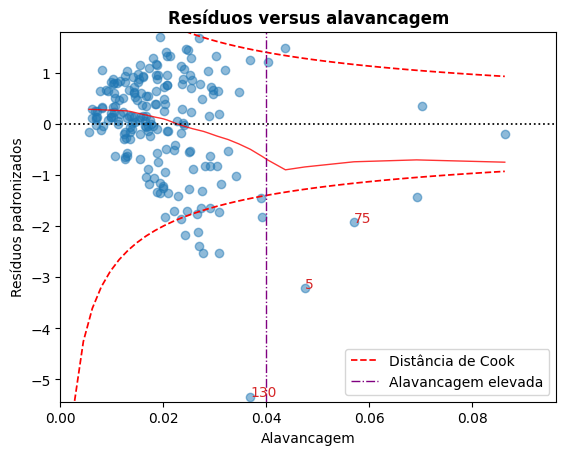

In [21]:
diagnostico.grafico_alavancagem(
    mostrar_limite_alavancagem=True, criterio_cook="graus_liberdade"
);

**E. VIF**

O fator de inflação da variância (VIF) é uma medida de multicolinearidade.

Um VIF > 5 para uma variável indica que ela é altamente colinear com as outras variáveis de entrada.

In [22]:
diagnostico.tabela_vif()

,Variável,Fator VIF
0,Intercept,1.00
1,Televisão,1.00
2,Rádio,1.14
3,Jornal,1.15


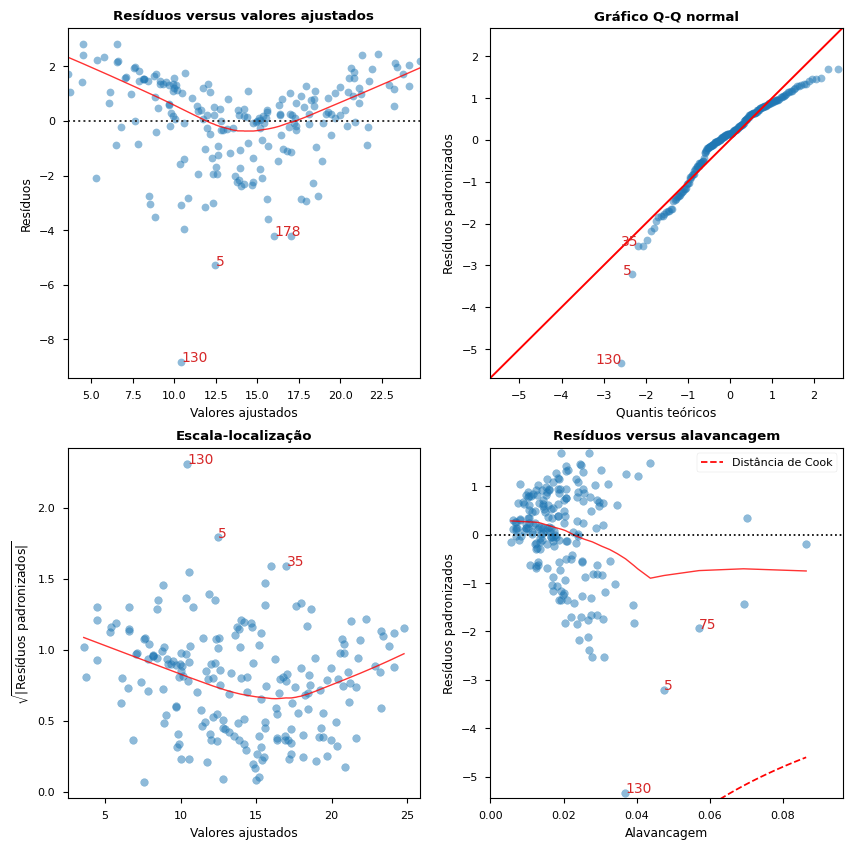

    Variável  Fator VIF
0  Intercept       1.00
1  Televisão       1.00
2      Rádio       1.14
3     Jornal       1.15


In [23]:
# Gerar todos os diagnósticos de uma só vez.
# Usar figura e eixos para ajustar a apresentação após a criação dos gráficos.
diagnostico = DiagnosticoRegressaoLinear(modelo)
tabela_vif, figura, eixos = diagnostico()
print(tabela_vif)

# Exemplo opcional para salvar a figura na pasta de execução:
# figura.savefig("diagnosticos_regressao_linear.png", dpi=150, bbox_inches="tight")

Para discussões detalhadas sobre a interpretação e as limitações dos gráficos acima, consulte o livro ISLR.